# 09. SQL — 메인 퀘스트 퍼널: 어디서 멈추고, 얼마나 걸리나

**입력**: `dataSets/starfield_achievements.csv` (업적 해금 이벤트 로그, 174만 행), `dataSets/starfield_analysis.csv`,
`dataSets/reviews_for_embedding.csv` (분석 대상 id), `dataSets/유저군집.csv` (06), `dataSets/추천확률.csv` (05b)
**출력**: `out/09_퍼널.png`, `out/09_단계별_소요시간.png`
**도구**: DuckDB — CSV를 그대로 테이블로 읽어 SQL로 질의한다 (`pip install duckdb`)

> 이 장은 발표(2026-10) 이후 추가한 후속 분석이다.

업적 데이터는 (유저, 이벤트, 시각) 세 열이 쌓인 **이벤트 로그**다. 메인 퀘스트 업적 10개는 순서가 정해져 있으므로 그대로 퍼널이 된다.
앞 장에서는 "리뷰 시점에 어디까지 갔나"만 썼고, **어디서 멈추는지·단계 사이에 얼마나 걸리는지**는 묻지 않았다.

**질문** Q4. 유저는 메인 퀘스트 어느 단계에서 멈추고, 단계 사이에 얼마나 걸리는가? 페르소나별로 다른가?
**가설** H3. 2단계(One Small Step) 직후가 가장 큰 이탈 구간이다 — 리뷰가 2단계에 42.8% 몰리고(06), 초기 리뷰어가 8시간·업적 3개 시점에 리뷰를 쓰는 것(06)과 맞물린다.

In [1]:
import os
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

os.makedirs('out', exist_ok=True)

# 한글 폰트: 폴더에 있는 폰트 파일을 쓰고, 없으면 맥 기본 폰트(AppleGothic)를 쓴다
FONT_FILE = 'helpers/fonts/NotoSansKR-Regular.ttf'
if os.path.exists(FONT_FILE):
    font_manager.fontManager.addfont(FONT_FILE)
    plt.rcParams['font.family'] = font_manager.FontProperties(fname=FONT_FILE).get_name()
else:
    plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

PERSONAS = ['하드 리뷰어', '초기 리뷰어', '라이트 리뷰어']
COLOR = {'하드 리뷰어': '#4C72B0', '초기 리뷰어': '#DD8452', '라이트 리뷰어': '#55A868', '전체': '#444444'}

COLLECTED_AT = 1788825600    # 수집 시점 2026-09-08 00:00 UTC. 관측 창 = 이 시각 − 리뷰 작성 시각

## 0. 테이블 적재

| 테이블 | 한 행 | 행 수 |
|---|---|---|
| `events` | 유저 한 명이 업적 하나를 해금한 이벤트 (steamid, name, t, stage) | 1,744,753 |
| `reviews` | 리뷰어 한 명 (리뷰·플레이타임·리뷰 시점 단계) — 분석 대상 70,915명만 | 70,915 |
| `persona` | 유저 한 명의 페르소나 (06) | 70,915 |
| `score` | 유저 한 명의 추천확률 (05b) | 70,915 |

`stage`는 메인 퀘스트 업적이면 1~10, 아니면 NULL (01에서 만든 열).

In [2]:
con = duckdb.connect()

con.execute("""
CREATE TABLE events AS
SELECT steamid, name, t, CAST(stage AS INTEGER) AS stage
FROM read_csv('dataSets/starfield_achievements.csv')
""")

# 분석 대상 id(03)로 걸러서 리뷰 테이블을 만든다
con.execute("""
CREATE TABLE reviews AS
SELECT r.steamid, r.ts_created, r.voted_up, r.language,
       r.playtime_at_review_min, r.playtime_forever_min,
       r.stage_at_review, r.stage_final, r.n_ach_at_review, r.n_ach_total
FROM read_csv('dataSets/starfield_analysis.csv', sample_size = -1) AS r
JOIN read_csv('dataSets/reviews_for_embedding.csv') AS p USING (steamid)
""")

con.execute("CREATE TABLE persona AS SELECT steamid, 페르소나 FROM read_csv('dataSets/유저군집.csv')")
con.execute("CREATE TABLE score AS SELECT steamid, 추천확률 FROM read_csv('dataSets/추천확률.csv')")

for table in ['events', 'reviews', 'persona', 'score']:
    n = con.execute(f'SELECT count(*) FROM {table}').fetchone()[0]
    print(f'{table:<8} {n:>10,} 행')

events    1,744,753 행
reviews      70,915 행
persona      70,915 행
score        70,915 행


In [3]:
# 이벤트 로그가 어떻게 생겼는지 한 사람 것만 본다
con.execute("""
SELECT steamid, name, stage, to_timestamp(t) AS unlocked_at
FROM events
WHERE steamid = (SELECT steamid FROM reviews WHERE stage_final = 10 LIMIT 1)
  AND stage IS NOT NULL
ORDER BY t
""").df()

,steamid,name,stage,unlocked_at
0,76561198007944105,"For All, Into the Starfield",1,2023-09-01 19:47:58+09:00
1,76561198007944105,One Small Step,2,2023-09-01 21:07:50+09:00
2,76561198007944105,Into the Unknown,3,2023-09-04 16:55:59+09:00
3,76561198007944105,All That Money Can Buy,4,2023-09-05 01:05:24+09:00
4,76561198007944105,Further Into the Unknown,5,2023-09-05 04:02:57+09:00
5,76561198007944105,High Price to Pay,6,2023-09-05 06:03:22+09:00
6,76561198007944105,In Their Footsteps,7,2023-09-05 07:05:35+09:00
7,76561198007944105,Entangled,8,2023-09-05 15:22:11+09:00
8,76561198007944105,Unearthed,9,2023-09-05 16:25:17+09:00
9,76561198007944105,One Giant Leap,10,2023-09-06 04:49:05+09:00


## 1. 검증 — 리뷰 시점 단계를 SQL로 다시 계산

01에서 pandas로 만든 `stage_at_review`(리뷰 작성 **전**에 해금한 메인 퀘스트 업적 중 가장 뒤 단계)를
JOIN + GROUP BY로 다시 계산해 전부 일치하는지 확인한다. 같은 방식으로 `n_ach_at_review`(리뷰 전 전체 업적 수)도 확인한다.

In [4]:
check = con.execute("""
WITH before_review AS (                                  -- 리뷰 작성 전에 해금한 업적만
    SELECT e.steamid, e.stage
    FROM events AS e
    JOIN reviews AS r USING (steamid)
    WHERE e.t < r.ts_created
),
recomputed AS (
    SELECT steamid,
           COALESCE(MAX(stage), 0) AS stage_sql,          -- 메인 퀘스트 업적이 없으면 0단계
           COUNT(*)               AS n_ach_sql
    FROM before_review
    GROUP BY steamid
)
SELECT COUNT(*)                                                                   AS n_reviewers,
       SUM(CASE WHEN r.stage_at_review = COALESCE(c.stage_sql, 0) THEN 1 ELSE 0 END) AS stage_match,
       SUM(CASE WHEN r.n_ach_at_review = COALESCE(c.n_ach_sql, 0) THEN 1 ELSE 0 END) AS n_ach_match
FROM reviews AS r
LEFT JOIN recomputed AS c USING (steamid)                 -- 리뷰 전 업적이 하나도 없는 사람은 LEFT JOIN으로 남긴다
""").df()
print(check)
print('stage_at_review 일치:', check['stage_match'][0] == check['n_reviewers'][0],
      '/ n_ach_at_review 일치:', check['n_ach_match'][0] == check['n_reviewers'][0])

   n_reviewers  stage_match  n_ach_match
0        70915      70915.0      70915.0
stage_at_review 일치: True / n_ach_at_review 일치: True


## 2. 관측 창 — 누구까지 퍼널에 넣을 수 있나

업적은 수집 시점(2026-09-08)까지의 상태다. 2023년에 리뷰를 쓴 사람은 3년을 관측했지만 2026년 리뷰어는 몇 주뿐이라,
"완주 못 함"이 이탈인지 아직 못 간 건지 구분이 안 된다(우측 검열). 리뷰 연도별로 완주율이 얼마나 다른지, 리뷰 후 해금이 보통 며칠 안에 끝나는지 본다.

In [5]:
con.execute(f"""
SELECT year(to_timestamp(ts_created))                                   AS review_year,
       COUNT(*)                                                           AS n,
       ROUND(MEDIAN(({COLLECTED_AT} - ts_created) / 86400.0))             AS obs_days_median,
       ROUND(100.0 * SUM(CASE WHEN stage_final >= 3  THEN 1 ELSE 0 END) / COUNT(*), 1) AS reach_stage3_pct,
       ROUND(100.0 * SUM(CASE WHEN stage_final = 10  THEN 1 ELSE 0 END) / COUNT(*), 1) AS reach_stage10_pct
FROM reviews
GROUP BY 1
ORDER BY 1
""").df()

,review_year,n,obs_days_median,reach_stage3_pct,reach_stage10_pct
0,2023,55669,1093.0,70.3,41.6
1,2024,11075,842.0,64.3,36.0
2,2025,1792,453.0,64.1,37.0
3,2026,2379,141.0,64.4,36.3


In [6]:
# 리뷰 이후에 해금된 메인 퀘스트 업적은 리뷰 후 며칠 안에 일어났나
con.execute("""
SELECT ROUND(quantile_cont((e.t - r.ts_created) / 86400.0, 0.50)) AS q50_days,
       ROUND(quantile_cont((e.t - r.ts_created) / 86400.0, 0.75)) AS q75_days,
       ROUND(quantile_cont((e.t - r.ts_created) / 86400.0, 0.90)) AS q90_days,
       ROUND(quantile_cont((e.t - r.ts_created) / 86400.0, 0.95)) AS q95_days
FROM events AS e
JOIN reviews AS r USING (steamid)
WHERE e.stage IS NOT NULL AND e.t > r.ts_created
""").df()

,q50_days,q75_days,q90_days,q95_days
0,10.0,37.0,282.0,519.0


리뷰 후 해금의 90%는 282일 안에 일어난다. 2024·2025·2026년 리뷰어의 완주율(36~37%)이 비슷한 것도 관측 창이 180일만 넘으면 퍼널이 거의 굳는다는 뜻이다.
2023년 리뷰어의 완주율(41.6%)이 높은 건 관측이 길어서라기보다 출시 직후 유저의 성향으로 보인다 → 퍼널에 코호트(리뷰 연도)를 같이 표시한다.

**퍼널 모집단: 관측 창 180일 이상인 리뷰어** (2026-03-12 이전 리뷰). 아래 뷰로 고정한다.

In [7]:
con.execute(f"""
CREATE VIEW funnel_pop AS
SELECT r.*, p.페르소나, s.추천확률,
       year(to_timestamp(r.ts_created)) AS review_year
FROM reviews AS r
JOIN persona AS p USING (steamid)
JOIN score   AS s USING (steamid)
WHERE ({COLLECTED_AT} - r.ts_created) / 86400.0 >= 180
""")
n_pop = con.execute('SELECT count(*) FROM funnel_pop').fetchone()[0]
print('퍼널 모집단', f'{n_pop:,}', '명 (전체 70,915명 중', f'{n_pop / 70915 * 100:.1f}%)')

퍼널 모집단 68,994 명 (전체 70,915명 중 97.3%)


## 3. 퍼널 — 단계별 도달률과 단계 전환율

각 유저의 최종 단계(`stage_final`)가 k 이상이면 k단계에 "도달"한 것이다.
- 도달률 = k단계 도달 인원 ÷ **모집단 전체**(`funnel_pop`) — 첫 메인 퀘스트 업적이 없는 0단계 유저도 분모에 들어간다(1단계 도달률이 100%가 아닌 이유, 5절 참조)
- 전환율 = k단계 도달 인원 ÷ (k−1)단계 도달 인원 → 어느 구간에서 가장 많이 빠지는지

In [8]:
funnel = con.execute("""
WITH stages AS (SELECT * FROM generate_series(1, 10) AS g(stage)),   -- 1~10 단계 표
reached AS (
    SELECT s.stage,
           SUM(CASE WHEN f.stage_final >= s.stage THEN 1 ELSE 0 END) AS n_reached
    FROM stages AS s
    CROSS JOIN funnel_pop AS f
    GROUP BY s.stage
)
SELECT stage,
       n_reached,
       ROUND(100.0 * n_reached / (SELECT COUNT(*) FROM funnel_pop), 1)                     AS reach_pct,
       ROUND(100.0 * n_reached / LAG(n_reached) OVER (ORDER BY stage), 1)                  AS step_conversion_pct,
       ROUND(100.0 - 100.0 * n_reached / LAG(n_reached) OVER (ORDER BY stage), 1)          AS step_drop_pct
FROM reached
ORDER BY stage
""").df()
print(funnel.to_string(index=False))

 stage  n_reached  reach_pct  step_conversion_pct  step_drop_pct
     1    68464.0       99.2                  NaN            NaN
     2    66200.0       96.0                 96.7            3.3
     3    47675.0       69.1                 72.0           28.0
     4    42547.0       61.7                 89.2           10.8
     5    38865.0       56.3                 91.3            8.7
     6    36920.0       53.5                 95.0            5.0
     7    34387.0       49.8                 93.1            6.9
     8    31607.0       45.8                 91.9            8.1
     9    31000.0       44.9                 98.1            1.9
    10    27953.0       40.5                 90.2            9.8


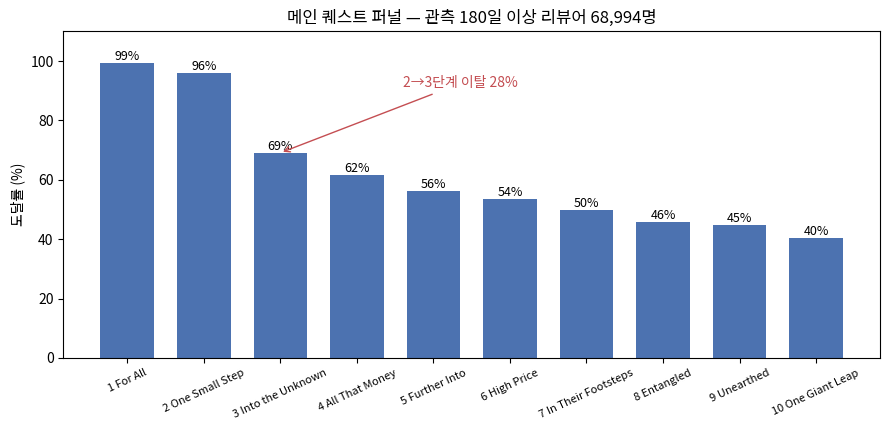

In [9]:
STAGE_NAMES = ['1 For All', '2 One Small Step', '3 Into the Unknown', '4 All That Money', '5 Further Into',
               '6 High Price', '7 In Their Footsteps', '8 Entangled', '9 Unearthed', '10 One Giant Leap']

fig, ax = plt.subplots(figsize=(9, 4.4))
bars = ax.bar(STAGE_NAMES, funnel['reach_pct'], color='#4C72B0', width=0.7)
ax.bar_label(bars, labels=[f'{v:.0f}%' for v in funnel['reach_pct']], fontsize=9)
# 가장 큰 이탈 구간 표시
worst = funnel.loc[funnel['step_drop_pct'].idxmax()]
ax.annotate(f"{int(worst['stage']) - 1}→{int(worst['stage'])}단계 이탈 {worst['step_drop_pct']:.0f}%",
            xy=(int(worst['stage']) - 1, worst['reach_pct']), xytext=(int(worst['stage']) + 0.6, worst['reach_pct'] + 22),
            color='#C44E52', fontsize=10, fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='#C44E52'))
ax.set_ylim(0, 110)
ax.set_ylabel('도달률 (%)')
ax.set_title(f'메인 퀘스트 퍼널 — 관측 180일 이상 리뷰어 {n_pop:,}명')
ax.tick_params(axis='x', labelsize=8, rotation=25)
fig.tight_layout()
fig.savefig('out/09_퍼널.png', dpi=150)
plt.show()

## 4. 단계 간 소요 시간 — 어디가 오래 걸리나

같은 사람의 메인 퀘스트 해금 이벤트를 단계 순서로 세워 두고, `LAG()`로 바로 앞 단계의 해금 시각을 가져와 차이를 구한다.
이 시간은 **실제 경과 시간**(벽시계)이라 플레이 시간보다 길다 — "중간에 쉬었다 돌아온 기간"까지 포함된다.
그래서 중앙값과 함께, 7일 넘게 걸린 비율(멈췄다가 돌아온 사람)을 같이 본다.

In [10]:
gaps = con.execute("""
WITH main_quest AS (
    SELECT e.steamid, e.stage, e.t
    FROM events AS e
    JOIN funnel_pop AS f USING (steamid)
    WHERE e.stage IS NOT NULL
),
with_prev AS (
    SELECT steamid, stage, t,
           LAG(t) OVER (PARTITION BY steamid ORDER BY stage) AS prev_t    -- 같은 사람의 바로 앞 단계 해금 시각
    FROM main_quest
)
SELECT stage,
       COUNT(*)                                                           AS n,
       ROUND(MEDIAN((t - prev_t) / 3600.0), 1)                            AS median_hours,
       ROUND(quantile_cont((t - prev_t) / 3600.0, 0.75), 1)               AS q75_hours,
       ROUND(100.0 * SUM(CASE WHEN t - prev_t > 7 * 86400 THEN 1 ELSE 0 END) / COUNT(*), 1) AS over_7days_pct
FROM with_prev
WHERE prev_t IS NOT NULL AND t >= prev_t          -- 순서가 뒤집힌 소수(8·9단계처럼 순서가 자유로운 구간)는 제외
  AND stage >= 2                                  -- 1단계는 앞 단계가 없다
GROUP BY stage
ORDER BY stage
""").df()
print(gaps.to_string(index=False))

 stage     n  median_hours  q75_hours  over_7days_pct
     2 62979           4.3       19.1             4.2
     3 44635         140.3      332.4            44.1
     4 41041          21.8       88.3            15.4
     5 37566          20.2       76.4            14.1
     6 35834           7.2       27.5             6.7
     7 33354           9.5       47.6            10.6
     8 30679          16.9       52.8            11.2
     9 30201           0.1        3.4             3.0
    10 27454           6.2       46.9            12.1


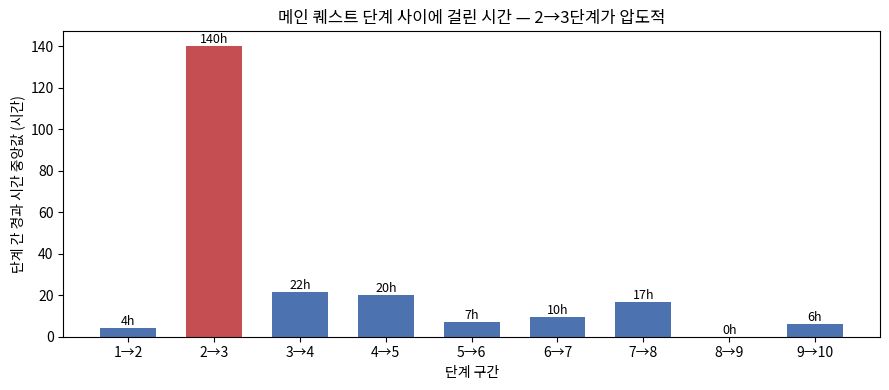

In [11]:
fig, ax = plt.subplots(figsize=(9, 4))
labels = [f'{s - 1}→{s}' for s in gaps['stage']]
colors = ['#C44E52' if h == gaps['median_hours'].max() else '#4C72B0' for h in gaps['median_hours']]
bars = ax.bar(labels, gaps['median_hours'], color=colors, width=0.65)
ax.bar_label(bars, labels=[f'{v:.0f}h' for v in gaps['median_hours']], fontsize=9)
ax.set_ylabel('단계 간 경과 시간 중앙값 (시간)')
ax.set_xlabel('단계 구간')
ax.set_title('메인 퀘스트 단계 사이에 걸린 시간 — 2→3단계가 압도적')
fig.tight_layout()
fig.savefig('out/09_단계별_소요시간.png', dpi=150)
plt.show()

2→3단계 사이가 중앙값 140시간(약 6일)으로 다른 구간(수 시간~하루)의 7배 이상이고, 44%는 7일 넘게 걸렸다(멈췄다가 돌아온 사람). 3단계(Into the Unknown)는 첫 행성 탐사 뒤 자유 탐험이 열리는 지점이라
여기서 사이드 콘텐츠로 빠지거나 아예 멈추는 사람이 많다. 가장 큰 이탈(2→3)과 가장 긴 소요 시간이 같은 구간에서 나온다.

## 5. 페르소나별 퍼널 — 같은 구간에서 빠지나

**분모가 3절과 다르다.** 여기서는 페르소나별 **1단계 도달 인원**을 100%로 둔다. 첫 메인 퀘스트 업적(For All, Into the Starfield)은 튜토리얼 직후에 뜨므로
그게 없는 0단계 유저는 "퍼널에 들어온 적이 없는 사람"(업적 비활성화·메인 퀘스트 미진행)으로 보고 제외한다. 이렇게 해야 세 선이 같은 점에서 출발해
이후 격차가 순수하게 단계 사이의 전환 차이로 읽힌다. 다만 0단계 유저는 초기 리뷰어에 몰려 있어(아래 표) 그 자체로 정보이므로 먼저 세어 둔다.
모집단 전체를 분모로 바꿔도 결론은 같다(3단계 도달률 라이트 82.2 / 하드 83.2 / 초기 36.5%).

In [12]:
# 5절 퍼널의 분모에서 빠지는 0단계 유저 — 수집 시점까지 첫 메인 퀘스트 업적이 없는 사람
con.execute("""
SELECT 페르소나,
       COUNT(*)                                                       AS n_pop,
       SUM(CASE WHEN stage_final = 0 THEN 1 ELSE 0 END)               AS n_stage0,
       ROUND(100.0 * SUM(CASE WHEN stage_final = 0 THEN 1 ELSE 0 END) / COUNT(*), 2) AS stage0_pct,
       ROUND(MEDIAN(CASE WHEN stage_final = 0 THEN n_ach_total END))  AS stage0_median_ach,     -- 다른 업적은 있는가
       ROUND(MEDIAN(CASE WHEN stage_final = 0 THEN playtime_forever_min END) / 60, 1) AS stage0_median_hours
FROM funnel_pop
GROUP BY 페르소나
ORDER BY stage0_pct DESC
""").df()

,페르소나,n_pop,n_stage0,stage0_pct,stage0_median_ach,stage0_median_hours
0,초기 리뷰어,20332,354.0,1.74,4.0,24.2
1,하드 리뷰어,25589,97.0,0.38,12.0,68.2
2,라이트 리뷰어,23073,79.0,0.34,9.0,60.1


In [13]:
by_persona = con.execute("""
WITH stages AS (SELECT * FROM generate_series(1, 10) AS g(stage)),
reached AS (
    SELECT f.페르소나, s.stage,
           SUM(CASE WHEN f.stage_final >= s.stage THEN 1 ELSE 0 END) AS n_reached
    FROM stages AS s
    CROSS JOIN funnel_pop AS f
    GROUP BY f.페르소나, s.stage
)
SELECT 페르소나, stage,
       ROUND(100.0 * n_reached / SUM(CASE WHEN stage = 1 THEN n_reached END) OVER (PARTITION BY 페르소나), 1) AS reach_pct,
       ROUND(100.0 * n_reached / LAG(n_reached) OVER (PARTITION BY 페르소나 ORDER BY stage), 1)             AS step_conversion_pct
FROM reached
ORDER BY 페르소나, stage
""").df()

# 보기 좋게: 행 = 단계, 열 = 페르소나
print('도달률 (%)')
print(by_persona.pivot(index='stage', columns='페르소나', values='reach_pct')[PERSONAS].to_string())
print()
print('단계 전환율 (%)')
print(by_persona.pivot(index='stage', columns='페르소나', values='step_conversion_pct')[PERSONAS].to_string())

도달률 (%)
페르소나   하드 리뷰어  초기 리뷰어  라이트 리뷰어
stage                         
1       100.0   100.0    100.0
2        99.7    89.5     99.6
3        83.5    37.1     82.5
4        75.6    29.9     75.3
5        69.5    25.9     69.4
6        66.5    23.8     66.2
7        62.1    21.7     61.9
8        57.7    19.2     56.7
9        56.8    18.7     55.6
10       52.0    16.3     49.8

단계 전환율 (%)
페르소나   하드 리뷰어  초기 리뷰어  라이트 리뷰어
stage                         
1         NaN     NaN      NaN
2        99.7    89.5     99.6
3        83.7    41.4     82.9
4        90.5    80.7     91.2
5        92.0    86.5     92.3
6        95.6    91.8     95.3
7        93.3    91.1     93.6
8        93.0    88.8     91.6
9        98.3    97.2     98.0
10       91.6    87.1     89.5


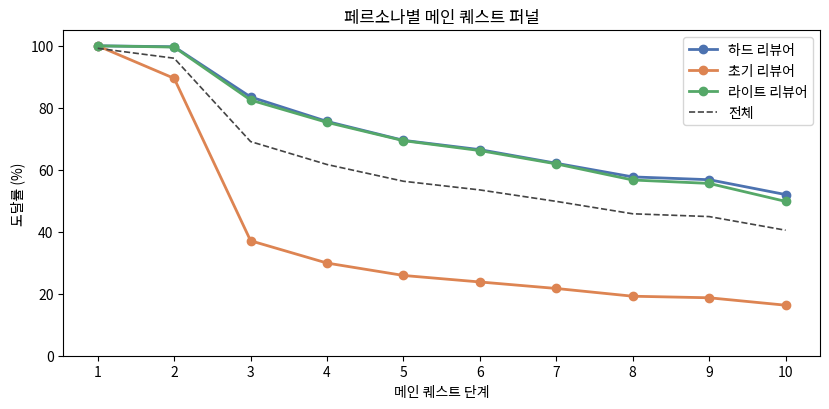

In [14]:
fig, ax = plt.subplots(figsize=(8.4, 4.2))
for name in PERSONAS:
    part = by_persona[by_persona['페르소나'] == name]
    ax.plot(part['stage'], part['reach_pct'], marker='o', lw=2, color=COLOR[name], label=name)
ax.plot(funnel['stage'], funnel['reach_pct'], ls='--', color=COLOR['전체'], lw=1.2, label='전체')
ax.set_xticks(range(1, 11))
ax.set_xlabel('메인 퀘스트 단계')
ax.set_ylabel('도달률 (%)')
ax.set_ylim(0, 105)
ax.set_title('페르소나별 메인 퀘스트 퍼널')
ax.legend()
fig.tight_layout()
fig.savefig('out/09_페르소나별_퍼널.png', dpi=150)
plt.show()

## 6. 리뷰 뒤에도 더 진행했나 — 리뷰 시점 단계 vs 최종 단계

7-5에서는 플레이시간으로 "리뷰 후 잔존"을 봤다. 여기서는 진행도로 본다: 리뷰 시점보다 최종 단계가 높으면 리뷰 뒤에도 메인 퀘스트를 더 진행한 것이다.
페르소나와 추천확률 구간(05b·07과 같은 0.3 / 0.7 경계)별로 비교한다.

In [15]:
con.execute("""
SELECT 페르소나,
       COUNT(*)                                                                              AS n,
       ROUND(100.0 * SUM(CASE WHEN stage_final > stage_at_review THEN 1 ELSE 0 END) / COUNT(*), 1) AS progressed_pct,
       ROUND(100.0 * SUM(CASE WHEN stage_final = 10 AND stage_at_review < 10 THEN 1 ELSE 0 END) / COUNT(*), 1) AS finished_after_review_pct
FROM funnel_pop
GROUP BY 페르소나
ORDER BY progressed_pct DESC
""").df()

,페르소나,n,progressed_pct,finished_after_review_pct
0,초기 리뷰어,20332,42.8,15.9
1,라이트 리뷰어,23073,40.6,24.4
2,하드 리뷰어,25589,40.2,25.3


In [16]:
con.execute("""
SELECT CASE WHEN 추천확률 < 0.3 THEN '부정 (<0.3)'
            WHEN 추천확률 < 0.7 THEN '중간'
            ELSE '긍정 (>=0.7)' END                                                             AS 구간,
       COUNT(*)                                                                              AS n,
       ROUND(100.0 * SUM(CASE WHEN stage_final > stage_at_review THEN 1 ELSE 0 END) / COUNT(*), 1) AS progressed_pct,
       ROUND(MEDIAN(stage_final - stage_at_review), 1)                                       AS median_stages_gained
FROM funnel_pop
WHERE stage_at_review < 10                        -- 이미 완주한 사람은 더 갈 곳이 없으니 제외
GROUP BY 1
ORDER BY MIN(추천확률)
""").df()

,구간,n,progressed_pct,median_stages_gained
0,부정 (<0.3),19774,31.3,0.0
1,중간,8702,48.9,0.0
2,긍정 (>=0.7),27899,64.2,2.0


## 7. 정리

- **H3 지지.** 2→3단계 전환율 72%(이탈 28%)로 가장 큰 이탈 구간이고, 나머지 구간은 이탈 2~11%다. 단계 간 경과 시간도 2→3이 중앙값 140시간으로 다른 구간의 7배 이상이다.
  초기 리뷰어가 2단계·8시간 시점에 가장 부정적인 리뷰를 쓰는 것(06·07)과 같은 지점이다.
- 세 페르소나 모두 2→3에서 빠지지만 크기가 다르다: 하드·라이트는 83%가 3단계에 도달하는데 **초기 리뷰어는 37%**뿐이다(전환율 41%). 3단계만 넘기면 이후 전환율은 세 유형이 80~98%로 비슷하다 → 초기 리뷰어의 문제는 "초반 한 구간"에 집중돼 있다.
- 리뷰 뒤 진행: 긍정 리뷰어(추천확률 ≥ 0.7)는 64%가 리뷰 뒤에도 메인 퀘스트를 더 진행(중앙값 2단계)하지만, 부정 리뷰어는 31%만 진행하고 중앙값은 0단계 → 부정 리뷰는 곧 이탈 신호.
  초기 리뷰어는 리뷰 뒤 진행 비율(43%)이 가장 높아 보이지만 일찍 리뷰를 써서 갈 곳이 많았던 것이고, 완주까지 간 비율은 16%로 가장 낮다.

**에이블리에 적용한다면**: 업적 이벤트 로그를 "가입 → 탐색 → 장바구니 → 결제" 이벤트 로그로 바꾸면 쿼리는 그대로 쓴다. 단계 전환율로 이탈 구간을 찾고, `LAG()`로 단계 간 체류 시간을 재고, 세그먼트별 퍼널을 비교하는 구조가 같다.

**한계**: 모집단은 업적 공개 리뷰어이며 관측 180일 미만 리뷰어는 제외했다(2,993명). 단계 간 시간은 실제 플레이 시간이 아니라 경과 시간이다. 8·9단계는 순서가 자유로워 뒤집힌 경우를 제외했다.